#Prédiction de l'acceptation des candidats à une licence d'excellence à l’aide du Machine Learning

In [ ]:
#installation des librairies
#Permet de lire et écrire des fichiers Excel (.xlsx)
!pip install openpyxl seaborn
!pip install -U imbalanced-learn
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 8.9 MB/s eta 0:00:00


In [ ]:
# Import des bibliothèques
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve, f1_score
from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.combine import SMOTETomek
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve, f1_score, ConfusionMatrixDisplay
from imblearn.under_sampling import RandomUnderSampler
from imblearn.ensemble import BalancedBaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

In [ ]:
# Affichage clair des dataframes
#Affiche toutes les colonnes du dataframe sans limitation
pd.set_option('display.max_columns', None)
# Lecture du fichier Excel
df = pd.read_excel('/content/Dataset_LEIA.xlsx')

In [ ]:
# Affichage des 5 premières lignes
df.head()

,id_ind,date_nais,sexe,situation_fam,etat,dat_bac,mention_bac,typLic,intitule,moydip,nbrannee_lic,mention_lic,etablissement,etablissementAutre,moysem1,nbmodvalsem1,nbmodvalsem1apr,moysem2,nbmodvalsem2,nbmodvalsem2apr,moysem3,nbmodvalsem3,nbmodvalsem3apr,moysem4,nbmodvalsem4,nbmodvalsem4apr,moysem5,nbmodvalsem5,nbmodvalsem5apr,id_fil,Champ35,date_ins,id,Champ38,cod_fil,lib_fil,cod_etab,cod_dip,idfu,libfu,id_univ,Champ46,cod_univ,lib_univ,Admission
0,2010,2001-06-14,M,celibataire,etudiant,2021,P,AUTRE,Dأ©veloppement digital option web full stack,17.37,2,TB,143,Ista-sefrou,15.38,7,0,15.38,7,0,17.37,6,0,17.37,6,0,0.0,0,0,1,2010,2024-08-10-11-39,2342,1,L,Licence d'Excellence en Intelligence Artificielle,NaN,NaN,143,Autre,17,17,AUT,Autre,Admis
1,3753,1989-11-07,M,celibataire,etudiant,2020,AB,DEUG,Licence fondamentale SMI,14.39,4,B,12,NaN,12.68,6,0,14.12,5,1,14.75,3,3,16.03,5,1,0.0,0,0,1,3753,2024-08-28-13-45,4527,1,L,Licence d'Excellence en Intelligence Artificielle,NaN,NaN,12,Facultأ© des Sciences Ben M'Sick - Casablanca,1,1,UH2M,Universitأ© آ Hassan II آ de Casablanca,Admis
2,3416,2004-11-11,M,celibataire,etudiant,2022,AB,AUTRE,Dأ©veloppement des systأ¨mes d'information,15.65,2,B,143,Brevet de Technicien Supأ©rieur,13.64,0,0,13.64,0,0,15.65,0,0,15.65,0,0,0.0,0,0,1,3416,2024-08-24-21-12,4103,1,L,Licence d'Excellence en Intelligence Artificielle,NaN,NaN,143,Autre,17,17,AUT,Autre,Admis
3,490,2001-02-26,F,celibataire,etudiant,2019,B,DUT,genie informatique,13.80,3,AB,142,NaN,13.25,2,2,13.39,3,1,14.71,4,0,13.86,2,2,0.0,0,0,1,490,2024-08-05-12-34,557,1,L,Licence d'Excellence en Intelligence Artificielle,NaN,NaN,142,Ecole Supأ©rieure de Technologie - Sidi Bennour,13,13,UCDE,"Universitأ© Choaib Doukkali, El Jadida",Admis
4,490,2001-02-26,F,celibataire,etudiant,2019,B,DUT,genie informatique,13.80,3,AB,142,NaN,13.25,2,2,13.39,3,1,14.71,4,0,13.86,2,2,0.0,0,0,1,490,2024-08-05-12-36,560,1,L,Licence d'Excellence en Intelligence Artificielle,NaN,NaN,142,Ecole Supأ©rieure de Technologie - Sidi Bennour,13,13,UCDE,"Universitأ© Choaib Doukkali, El Jadida",Admis


In [ ]:
# Dimensions du dataset
print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

# Infos générales sur les colonnes (type de données, valeurs manquantes...)
df.info()


Nombre de lignes : 5401
Nombre de colonnes : 45
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5401 entries, 0 to 5400
Data columns (total 45 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id_ind              5401 non-null   int64         
 1   date_nais           5398 non-null   datetime64[ns]
 2   sexe                5401 non-null   object        
 3   situation_fam       5401 non-null   object        
 4   etat                5401 non-null   object        
 5   dat_bac             5401 non-null   int64         
 6   mention_bac         5401 non-null   object        
 7   typLic              5401 non-null   object        
 8   intitule            5401 non-null   object        
 9   moydip              5401 non-null   float64       
 10  nbrannee_lic        5401 non-null   int64         
 11  mention_lic         5401 non-null   object        
 12  etablissement       5401 non-null   int64         
 13  

In [ ]:
# Statistiques pour les colonnes numériques
df.describe()

,id_ind,date_nais,dat_bac,moydip,nbrannee_lic,etablissement,moysem1,nbmodvalsem1,nbmodvalsem1apr,moysem2,nbmodvalsem2,nbmodvalsem2apr,moysem3,nbmodvalsem3,nbmodvalsem3apr,moysem4,nbmodvalsem4,nbmodvalsem4apr,moysem5,nbmodvalsem5,nbmodvalsem5apr,id_fil,Champ35,id,Champ38,cod_etab,cod_dip,idfu,id_univ,Champ46
count,5401.000000,5398,5401.000000,5401.000000,5401.000000,5401.000000,5401.000000,5401.000000,5401.000000,5401.000000,5401.000000,5401.000000,5401.000000,5401.000000,5401.000000,5401.000000,5401.000000,5401.000000,5401.0,5401.0,5401.0,5401.0,5401.000000,5401.000000,5401.0,0.0,0.0,5401.000000,5401.000000,5401.000000
mean,2174.812442,2003-01-15 19:26:17.917747200,2020.686910,13.949896,2.104055,116.487132,13.442925,4.308832,0.697278,13.489578,4.291242,0.703018,14.123784,3.887243,0.601926,14.340942,3.970006,0.529717,0.0,0.0,0.0,1.0,2174.812442,2714.829291,1.0,NaN,NaN,116.487132,13.274579,13.274579
min,2.000000,1972-12-19 00:00:00,1996.000000,10.000000,2.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,1.0,2.000000,12.000000,1.0,NaN,NaN,3.000000,1.000000,1.000000
25%,1048.000000,2002-06-04 06:00:00,2020.000000,12.800000,2.000000,100.000000,12.230000,2.000000,0.000000,12.250000,2.000000,0.000000,12.880000,2.000000,0.000000,13.280000,3.000000,0.000000,0.0,0.0,0.0,1.0,1048.000000,1365.000000,1.0,NaN,NaN,100.000000,8.000000,8.000000
50%,2153.000000,2003-09-08 00:00:00,2021.000000,13.980000,2.000000,143.000000,13.450000,4.000000,0.000000,13.490000,4.000000,0.000000,14.370000,4.000000,0.000000,14.740000,4.000000,0.000000,0.0,0.0,0.0,1.0,2153.000000,2715.000000,1.0,NaN,NaN,143.000000,17.000000,17.000000
75%,3279.000000,2004-07-14 00:00:00,2022.000000,15.190000,2.000000,143.000000,14.870000,7.000000,0.000000,14.970000,7.000000,0.000000,15.700000,6.000000,0.000000,15.890000,6.000000,0.000000,0.0,0.0,0.0,1.0,3279.000000,4066.000000,1.0,NaN,NaN,143.000000,17.000000,17.000000
max,4454.000000,2024-12-12 00:00:00,2022.000000,20.000000,4.000000,143.000000,19.510000,7.000000,7.000000,19.510000,7.000000,7.000000,20.000000,6.000000,6.000000,20.000000,6.000000,6.000000,0.0,0.0,0.0,1.0,4454.000000,5418.000000,1.0,NaN,NaN,143.000000,17.000000,17.000000
std,1284.637378,NaN,2.163055,1.834878,0.356818,45.258900,2.262901,2.760196,1.588270,2.281388,2.761001,1.599516,2.373271,2.357743,1.413961,2.400485,2.330758,1.406696,0.0,0.0,0.0,0.0,1284.637378,1560.407542,0.0,NaN,NaN,45.258900,6.000861,6.000861


In [ ]:
# Aperçu des colonnes non numériques
df.select_dtypes(include='object').describe()

,sexe,situation_fam,etat,mention_bac,typLic,intitule,mention_lic,etablissementAutre,date_ins,cod_fil,lib_fil,libfu,cod_univ,lib_univ,Admission
count,5401,5401,5401,5401,5401,5401,5401,3551,5401,5401,5401,5401,5401,5401,185
unique,2,2,2,4,4,2498,4,2212,4682,1,1,57,14,14,1
top,M,celibataire,etudiant,AB,AUTRE,DTS,AB,OFPPT,2024-08-05-21-59,L,Licence d'Excellence en Intelligence Artificielle,Autre,AUT,Autre,Admis
freq,3058,5333,5096,1982,3383,329,2050,96,6,5401,5401,3551,3551,3551,185


In [ ]:
# Valeurs manquantes par colonne
print("Valeurs manquantes :")
print(df.isnull().sum())

Valeurs manquantes :
id_ind                   0
date_nais                3
sexe                     0
situation_fam            0
etat                     0
dat_bac                  0
mention_bac              0
typLic                   0
intitule                 0
moydip                   0
nbrannee_lic             0
mention_lic              0
etablissement            0
etablissementAutre    1850
moysem1                  0
nbmodvalsem1             0
nbmodvalsem1apr          0
moysem2                  0
nbmodvalsem2             0
nbmodvalsem2apr          0
moysem3                  0
nbmodvalsem3             0
nbmodvalsem3apr          0
moysem4                  0
nbmodvalsem4             0
nbmodvalsem4apr          0
moysem5                  0
nbmodvalsem5             0
nbmodvalsem5apr          0
id_fil                   0
Champ35                  0
date_ins                 0
id                       0
Champ38                  0
cod_fil                  0
lib_fil                  0
cod_eta

In [ ]:
# Nombre de doublons
print("\nNombre de doublons :", df.duplicated().sum())


Nombre de doublons : 0


In [ ]:
# Nombre de valeurs uniques par colonne
df.nunique().sort_values()

,0
cod_etab,0
cod_dip,0
nbmodvalsem5,1
moysem5,1
cod_fil,1
Champ38,1
id_fil,1
nbmodvalsem5apr,1
Admission,1
lib_fil,1


In [ ]:
# Remplacer les valeurs manquantes de la colonne Admission par "Non Admis"
df['Admission'] = df['Admission'].fillna('Non Admis')

# Vérification
print(df['Admission'].value_counts())

Admission
Non Admis    5216
Admis         185
Name: count, dtype: int64


In [ ]:
colonnes_a_supprimer = [
    'id', 'id_ind', 'Champ35', 'Champ38', 'Champ46', 'id_fil', 'idfu', 'id_univ',
    'cod_etab', 'cod_dip', 'intitule', 'etablissementAutre', 'date_nais',
    'date_ins','lib_fil', 'cod_fil', 'etablissement', 'cod_univ','lib_univ'
]

# Suppression des colonnes
df.drop(columns=colonnes_a_supprimer, inplace=True)

In [ ]:
print("Colonnes restantes :", df.columns.tolist())
print("Dimensions du dataframe :", df.shape)

Colonnes restantes : ['sexe', 'situation_fam', 'etat', 'dat_bac', 'mention_bac', 'typLic', 'moydip', 'nbrannee_lic', 'mention_lic', 'moysem1', 'nbmodvalsem1', 'nbmodvalsem1apr', 'moysem2', 'nbmodvalsem2', 'nbmodvalsem2apr', 'moysem3', 'nbmodvalsem3', 'nbmodvalsem3apr', 'moysem4', 'nbmodvalsem4', 'nbmodvalsem4apr', 'moysem5', 'nbmodvalsem5', 'nbmodvalsem5apr', 'libfu', 'Admission']
Dimensions du dataframe : (5401, 26)


In [ ]:
# Vérifier les valeurs manquantes restantes
print(df.isnull().sum())

sexe               0
situation_fam      0
etat               0
dat_bac            0
mention_bac        0
typLic             0
moydip             0
nbrannee_lic       0
mention_lic        0
moysem1            0
nbmodvalsem1       0
nbmodvalsem1apr    0
moysem2            0
nbmodvalsem2       0
nbmodvalsem2apr    0
moysem3            0
nbmodvalsem3       0
nbmodvalsem3apr    0
moysem4            0
nbmodvalsem4       0
nbmodvalsem4apr    0
moysem5            0
nbmodvalsem5       0
nbmodvalsem5apr    0
libfu              0
Admission          0
dtype: int64


In [ ]:
# Transformer la colonne Admission : 1 = Admis, 0 = Non Admis
df['Admission'] = df['Admission'].apply(lambda x: 1 if x == 'Admis' else 0)

# Vérification du résultat
print(df['Admission'].value_counts())

Admission
0    5216
1     185
Name: count, dtype: int64


In [ ]:
# Revenir temporairement aux libellés texte pour la visualisation
df['Admission'] = df['Admission'].apply(lambda x: 'Admis' if x == 1 else 'Non Admis')

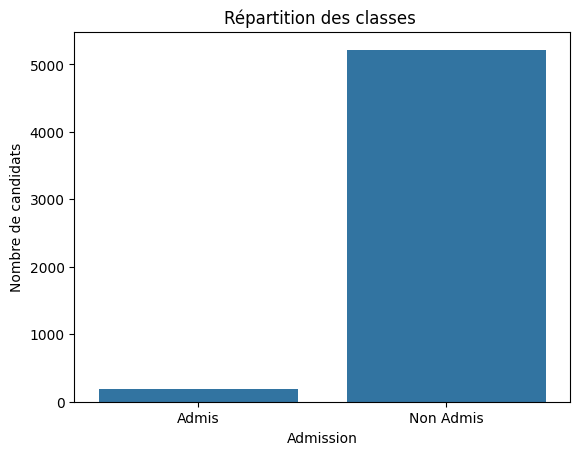

In [ ]:
sns.countplot(x='Admission', data=df)
plt.title("Répartition des classes ")
plt.xlabel("Admission")
plt.ylabel("Nombre de candidats")
plt.show()

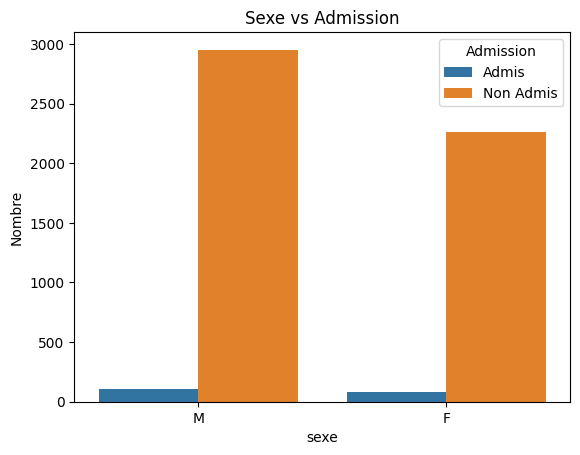

In [ ]:
sns.countplot(x='sexe', hue='Admission', data=df)
plt.title("Sexe vs Admission")
plt.ylabel("Nombre")
plt.show()

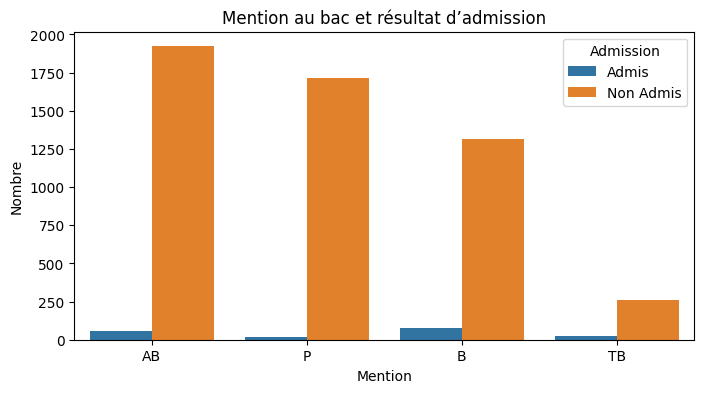

In [ ]:
plt.figure(figsize=(8, 4))
sns.countplot(x='mention_bac', hue='Admission', data=df, order=df['mention_bac'].value_counts().index)
plt.title("Mention au bac et résultat d’admission")
plt.xlabel("Mention")
plt.ylabel("Nombre")
plt.show()

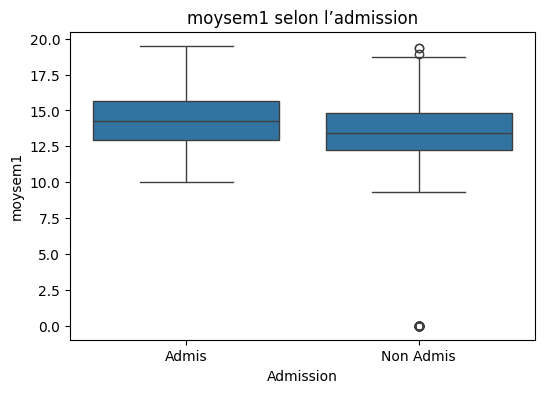

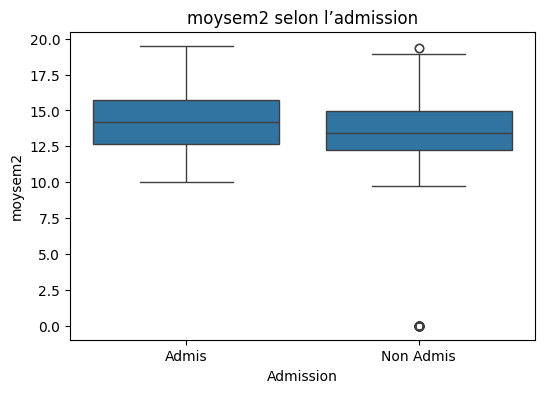

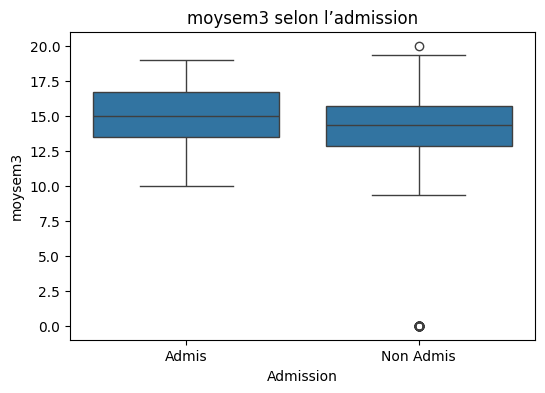

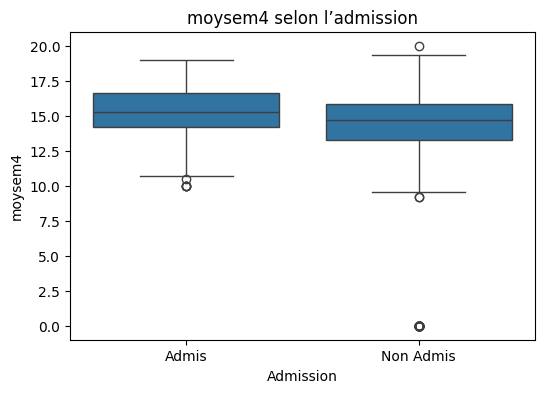

In [ ]:
semestres = ['moysem1', 'moysem2', 'moysem3', 'moysem4']

for col in semestres:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x='Admission', y=col, data=df)
    plt.title(f"{col} selon l’admission")
    plt.show()

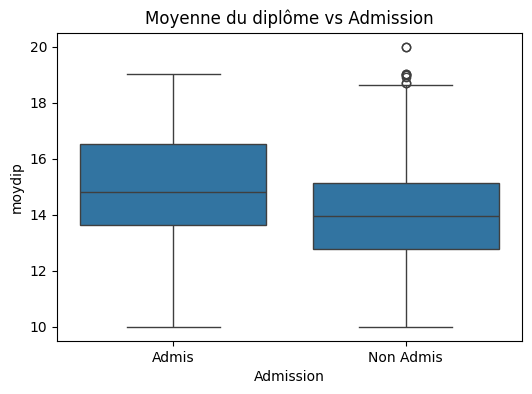

In [ ]:
plt.figure(figsize=(6, 4))
sns.boxplot(x='Admission', y='moydip', data=df)
plt.title("Moyenne du diplôme vs Admission")
plt.show()

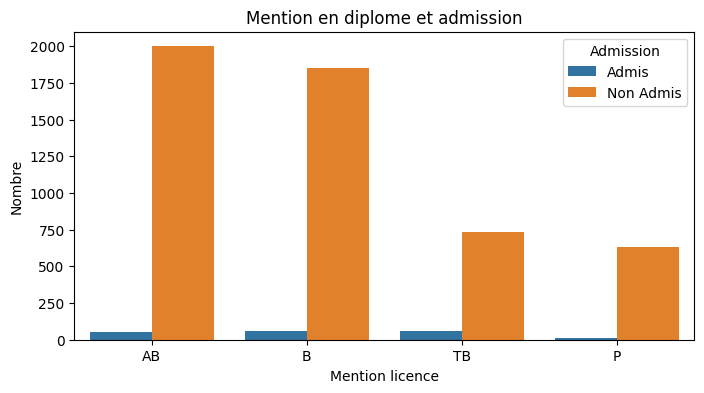

In [ ]:
plt.figure(figsize=(8, 4))
sns.countplot(x='mention_lic', hue='Admission', data=df, order=df['mention_lic'].value_counts().index)
plt.title("Mention en diplome et admission")
plt.xlabel("Mention licence")
plt.ylabel("Nombre")
plt.show()

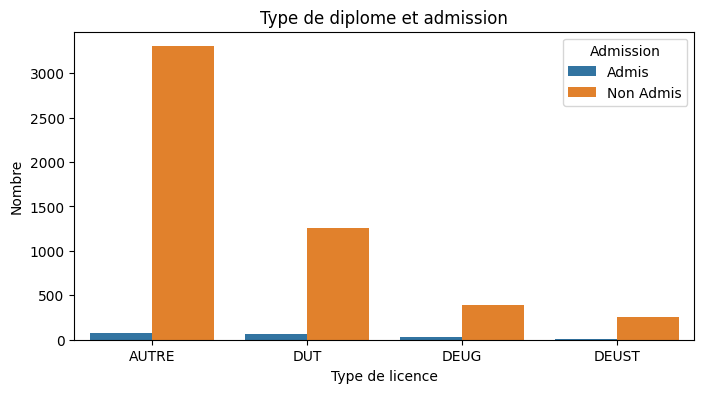

In [ ]:
plt.figure(figsize=(8, 4))
sns.countplot(x='typLic', hue='Admission', data=df, order=df['typLic'].value_counts().index)
plt.title("Type de diplome et admission")
plt.xlabel("Type de licence")
plt.ylabel("Nombre")
plt.show()

In [ ]:
colonnes_semestre5 = ['moysem5', 'nbmodvalsem5', 'nbmodvalsem5apr']
df.drop(columns=colonnes_semestre5, inplace=True)

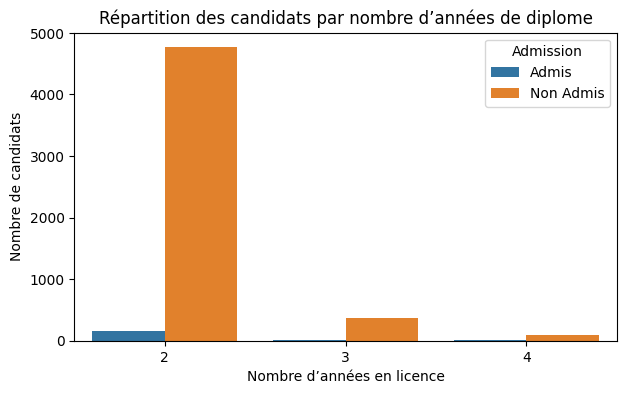

In [ ]:
# Countplot : répartition du nombre d'années selon les classes
plt.figure(figsize=(7, 4))
sns.countplot(x='nbrannee_lic', hue='Admission', data=df)
plt.title("Répartition des candidats par nombre d’années de diplome")
plt.xlabel("Nombre d’années en licence")
plt.ylabel("Nombre de candidats")
plt.show()

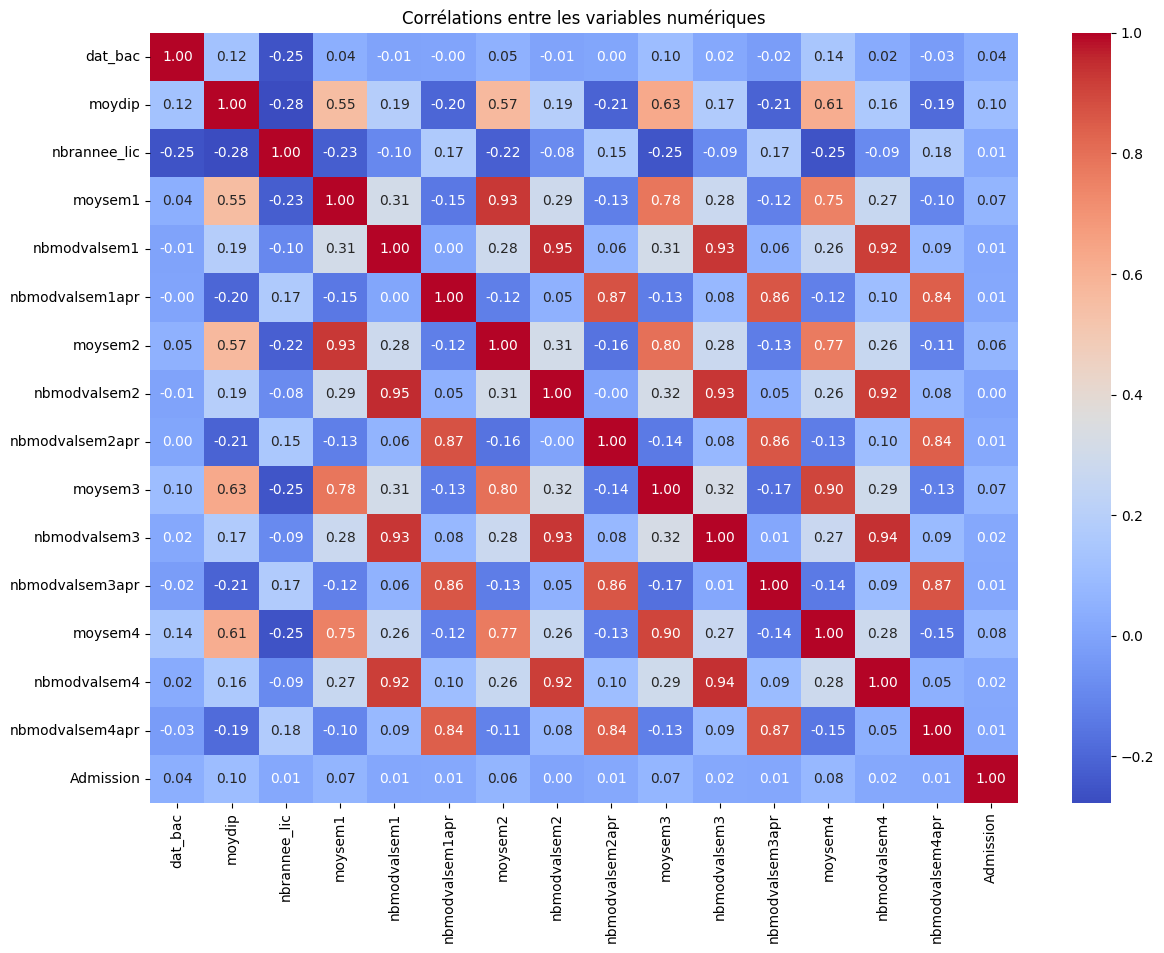

In [ ]:
# Transformer la colonne Admission : 1 = Admis, 0 = Non Admis
df['Admission'] = df['Admission'].apply(lambda x: 1 if x == 'Admis' else 0)

plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Corrélations entre les variables numériques")
plt.show()

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Liste des colonnes catégorielles
colonnes_cat = ['sexe', 'situation_fam', 'etat', 'mention_bac',
                'typLic', 'mention_lic', 'libfu']


label_encoders = {}

# Appliquer l'encodage à chaque colonne
for col in colonnes_cat:
    le = LabelEncoder()  # ← créer un nouvel encodeur à chaque itération
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le  # ← stocker le bon encodeur

print("✅ Encodage terminé.")
df.head()

✅ Encodage terminé.


,sexe,situation_fam,etat,dat_bac,mention_bac,typLic,moydip,nbrannee_lic,mention_lic,moysem1,nbmodvalsem1,nbmodvalsem1apr,moysem2,nbmodvalsem2,nbmodvalsem2apr,moysem3,nbmodvalsem3,nbmodvalsem3apr,moysem4,nbmodvalsem4,nbmodvalsem4apr,libfu,Admission
0,1,0,0,2021,2,0,17.37,2,3,15.38,7,0,15.38,7,0,17.37,6,0,17.37,6,0,0,1
1,1,0,0,2020,0,1,14.39,4,1,12.68,6,0,14.12,5,1,14.75,3,3,16.03,5,1,46,1
2,1,0,0,2022,0,0,15.65,2,1,13.64,0,0,13.64,0,0,15.65,0,0,15.65,0,0,0,1
3,0,0,0,2019,1,3,13.80,3,0,13.25,2,2,13.39,3,1,14.71,4,0,13.86,2,2,26,1
4,0,0,0,2019,1,3,13.80,3,0,13.25,2,2,13.39,3,1,14.71,4,0,13.86,2,2,26,1


In [ ]:
from sklearn.preprocessing import StandardScaler

# On sépare d'abord X et y
X = df.drop(columns=['Admission'])
y = df['Admission']

# Standardisation
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("✅ Données normalisées (prêtes pour la modélisation).")

✅ Données normalisées (prêtes pour la modélisation).


In [ ]:
from sklearn.model_selection import train_test_split

# X = variables explicatives / y = variable cible
X = df.drop(columns=['Admission'])
y = df['Admission']

# Étape 1 : split temporaire Train+Val / Test (80% / 20%)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# Étape 2 : split Train / Validation (75% / 25% de 80% = 60% / 20%)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42)

# Vérification
print(f"Train: {X_train.shape}")
print(f"Validation: {X_val.shape}")
print(f"Test: {X_test.shape}")


Train: (3240, 22)
Validation: (1080, 22)
Test: (1081, 22)


In [ ]:
print("Répartition des classes (train) :", y_train.value_counts())
print("Répartition des classes (val)   :", y_val.value_counts())
print("Répartition des classes (test)  :", y_test.value_counts())

Répartition des classes (train) : Admission
0    3129
1     111
Name: count, dtype: int64
Répartition des classes (val)   : Admission
0    1043
1      37
Name: count, dtype: int64
Répartition des classes (test)  : Admission
0    1044
1      37
Name: count, dtype: int64



🎯 Répartition des classes après SMOTE :
Admission
0    3129
1    3129
Name: count, dtype: int64

📊 Évaluation sur le jeu de validation :
              precision    recall  f1-score   support

   Non Admis       0.98      0.70      0.82      1043
       Admis       0.06      0.57      0.11        37

    accuracy                           0.70      1080
   macro avg       0.52      0.64      0.47      1080
weighted avg       0.95      0.70      0.80      1080



/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


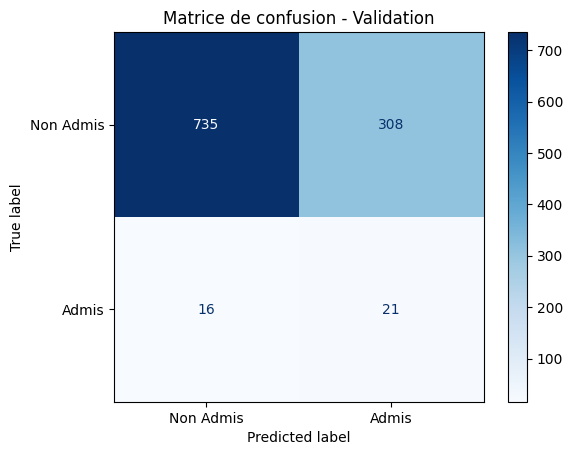


✅ Évaluation finale sur le jeu de test :
              precision    recall  f1-score   support

   Non Admis       0.98      0.67      0.79      1044
       Admis       0.06      0.65      0.12        37

    accuracy                           0.67      1081
   macro avg       0.52      0.66      0.46      1081
weighted avg       0.95      0.67      0.77      1081



In [ ]:
# 2️⃣ SMOTE : équilibrer le jeu d'entraînement uniquement
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print("\n🎯 Répartition des classes après SMOTE :")
print(y_train_res.value_counts())

# 3️⃣ Modèle avec pondération des classes
model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
model.fit(X_train_res, y_train_res)

# 4️⃣ Évaluation sur validation
y_val_pred = model.predict(X_val)
print("\n📊 Évaluation sur le jeu de validation :")
print(classification_report(y_val, y_val_pred, target_names=['Non Admis', 'Admis']))

# Matrice de confusion
cm = confusion_matrix(y_val, y_val_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non Admis', 'Admis'])
disp.plot(cmap='Blues')
plt.title("Matrice de confusion - Validation")
plt.show()

# 5️⃣ Évaluation finale sur test (facultatif ici)
y_test_pred = model.predict(X_test)
print("\n✅ Évaluation finale sur le jeu de test :")
print(classification_report(y_test, y_test_pred, target_names=['Non Admis', 'Admis']))



🔵 Entraînement du modèle : Random Forest
              precision    recall  f1-score   support

   Non Admis       0.98      0.97      0.97      1043
       Admis       0.30      0.32      0.31        37

    accuracy                           0.95      1080
   macro avg       0.64      0.65      0.64      1080
weighted avg       0.95      0.95      0.95      1080



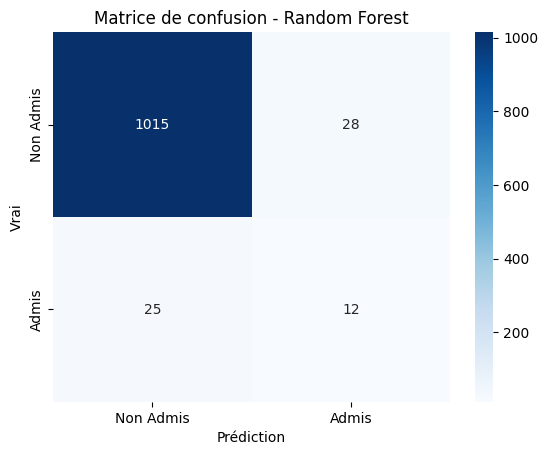


🔵 Entraînement du modèle : SVM (RBF kernel)
              precision    recall  f1-score   support

   Non Admis       0.98      0.84      0.91      1043
       Admis       0.09      0.46      0.16        37

    accuracy                           0.83      1080
   macro avg       0.54      0.65      0.53      1080
weighted avg       0.95      0.83      0.88      1080



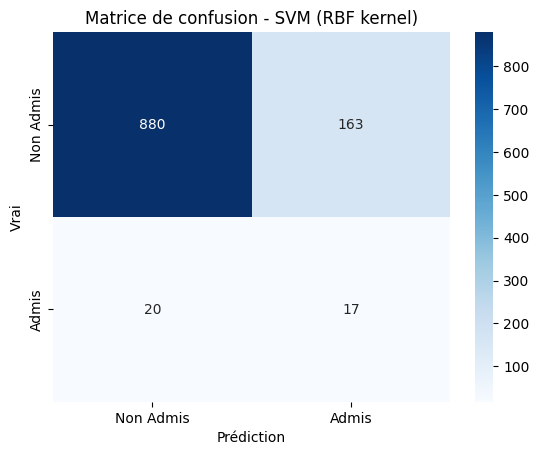


🔵 Entraînement du modèle : KNN
              precision    recall  f1-score   support

   Non Admis       0.98      0.87      0.92      1043
       Admis       0.12      0.51      0.20        37

    accuracy                           0.86      1080
   macro avg       0.55      0.69      0.56      1080
weighted avg       0.95      0.86      0.90      1080



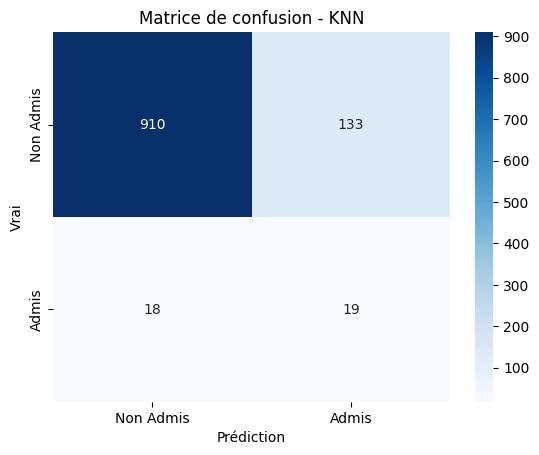


✅ Comparatif des modèles :


,Modèle,Accuracy,Precision,Recall,F1-score
0,Random Forest,0.951,0.300,0.324,0.312
2,KNN,0.860,0.125,0.514,0.201
1,SVM (RBF kernel),0.831,0.094,0.459,0.157


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score
# 📚 Liste des modèles à tester
models = {
    "Random Forest": RandomForestClassifier(class_weight='balanced', n_estimators=100, random_state=42),
    "SVM (RBF kernel)": make_pipeline(StandardScaler(), SVC(class_weight='balanced', probability=True, random_state=42)),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
}

# 📊 Comparer les performances
results = []

for name, model in models.items():
    print(f"\n🔵 Entraînement du modèle : {name}")
    model.fit(X_train_res, y_train_res)

    y_pred = model.predict(X_val)

    acc = accuracy_score(y_val, y_pred)
    prec = precision_score(y_val, y_pred, zero_division=0)
    rec = recall_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred)

    results.append({
        "Modèle": name,
        "Accuracy": round(acc, 3),
        "Precision": round(prec, 3),
        "Recall": round(rec, 3),
        "F1-score": round(f1, 3)
    })

    print(classification_report(y_val, y_pred, target_names=["Non Admis", "Admis"]))

    cm = confusion_matrix(y_val, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Non Admis", "Admis"], yticklabels=["Non Admis", "Admis"])
    plt.title(f"Matrice de confusion - {name}")
    plt.xlabel("Prédiction")
    plt.ylabel("Vrai")
    plt.show()

# 📊 Tableau récapitulatif des scores
import pandas as pd
results_df = pd.DataFrame(results)
print("\n✅ Comparatif des modèles :")
display(results_df.sort_values(by='F1-score', ascending=False))


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [11:35:56] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-

✅ Résumé comparatif sur validation :


,Méthode,Modèle,Accuracy,Recall,F1-score
1,class_weight,RandomForestClassifier,0.974,0.270,0.417
3,class_weight,XGBClassifier,0.957,0.297,0.324
5,SMOTE,RandomForestClassifier,0.951,0.324,0.312
9,SMOTE+Tomek,RandomForestClassifier,0.948,0.297,0.282
7,SMOTE,XGBClassifier,0.912,0.486,0.275
8,Undersampling,RandomForestClassifier,0.732,0.865,0.181
10,BalancedBagging,BalancedBaggingClassifier,0.805,0.622,0.179
2,class_weight,Pipeline,0.773,0.703,0.175
6,SMOTE,Pipeline,0.831,0.459,0.157
0,class_weight,LogisticRegression,0.691,0.703,0.135


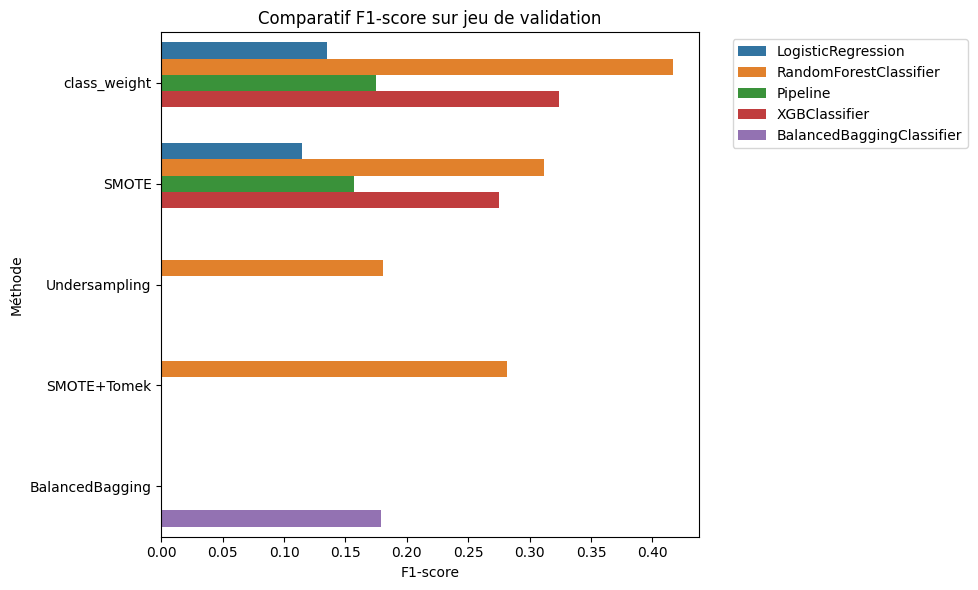

In [ ]:
# 📦 Modèles à tester selon la méthode
def get_models(class_weight=None):
    return {
        "LogReg": LogisticRegression(class_weight=class_weight, max_iter=1000, random_state=42),
        "RandomForest": RandomForestClassifier(class_weight=class_weight, n_estimators=100, random_state=42),
        "SVM": make_pipeline(StandardScaler(), SVC(class_weight=class_weight, probability=True, random_state=42)),
        "XGBoost": XGBClassifier(scale_pos_weight=28, use_label_encoder=False, eval_metric='logloss', random_state=42)
    }

# 📊 Évaluer un modèle sur la validation set
def evaluate_model(name, model, X_train_set, y_train_set):
    model.fit(X_train_set, y_train_set)
    y_pred = model.predict(X_val)
    return {
        "Méthode": name,
        "Modèle": model.__class__.__name__,
        "Accuracy": round(accuracy_score(y_val, y_pred), 3),
        "Recall": round(recall_score(y_val, y_pred), 3),
        "F1-score": round(f1_score(y_val, y_pred), 3)
    }

# 📌 Entraînement & évaluation de chaque méthode
results = []

# 1️⃣ class_weight='balanced'
for model_name, model in get_models('balanced').items():
    results.append(evaluate_model("class_weight", model, X_train, y_train))

# 2️⃣ SMOTE
X_sm, y_sm = SMOTE(random_state=42).fit_resample(X_train, y_train)
for model_name, model in get_models(None).items():
    results.append(evaluate_model("SMOTE", model, X_sm, y_sm))

# 3️⃣ Undersampling
X_us, y_us = RandomUnderSampler(random_state=42).fit_resample(X_train, y_train)
results.append(evaluate_model("Undersampling", RandomForestClassifier(random_state=42), X_us, y_us))

# 4️⃣ SMOTE + Tomek
X_st, y_st = SMOTETomek(random_state=42).fit_resample(X_train, y_train)
results.append(evaluate_model("SMOTE+Tomek", RandomForestClassifier(random_state=42), X_st, y_st))

# 5️⃣ BalancedBaggingClassifier
bbc = BalancedBaggingClassifier(
    estimator=DecisionTreeClassifier(),
    random_state=42)
results.append(evaluate_model("BalancedBagging", bbc, X_train, y_train))

# 🧾 Résultats finaux
results_df = pd.DataFrame(results)
print("✅ Résumé comparatif sur validation :")
display(results_df.sort_values(by='F1-score', ascending=False))

# 🧩 Visualisation
plt.figure(figsize=(10, 6))
sns.barplot(data=results_df, x='F1-score', y='Méthode', hue='Modèle')
plt.title("Comparatif F1-score sur jeu de validation")
plt.xlabel("F1-score")
plt.ylabel("Méthode")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


🔄 Rééchantillonnage : SMOTE
Distribution :
Admission
0    3129
1    3129
Name: count, dtype: int64

🌟 Modèle: XGBoost avec SMOTE
              precision    recall  f1-score   support

   Non Admis       0.97      0.99      0.98      1043
       Admis       0.60      0.24      0.35        37

    accuracy                           0.97      1080
   macro avg       0.79      0.62      0.67      1080
weighted avg       0.96      0.97      0.96      1080



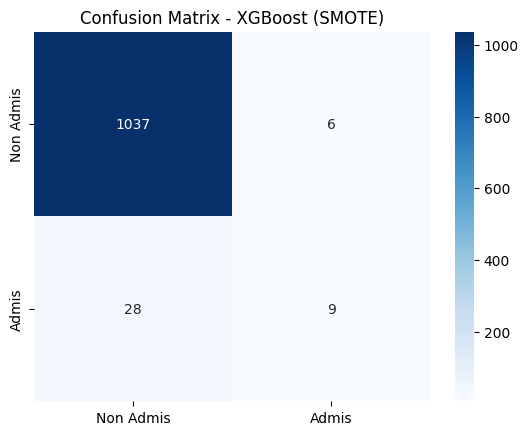


🌟 Modèle: LightGBM avec SMOTE
[LightGBM] [Info] Number of positive: 3129, number of negative: 3129
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001854 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1422
[LightGBM] [Info] Number of data points in the train set: 6258, number of used features: 22
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
              precision    recall  f1-score   support

   Non Admis       0.98      0.97      0.97      1043
       Admis       0.29      0.35      0.32        37

    accuracy                           0.95      1080
   macro avg       0.63      0.66      0.65      1080
weighted avg       0.95      0.95      0.95      1080



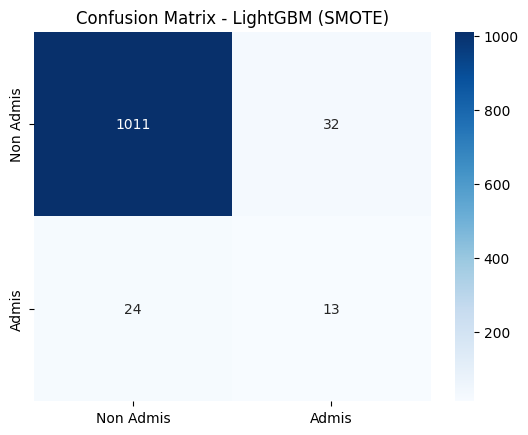


🌟 Modèle: CatBoost avec SMOTE
              precision    recall  f1-score   support

   Non Admis       0.98      0.98      0.98      1043
       Admis       0.35      0.32      0.34        37

    accuracy                           0.96      1080
   macro avg       0.66      0.65      0.66      1080
weighted avg       0.95      0.96      0.96      1080



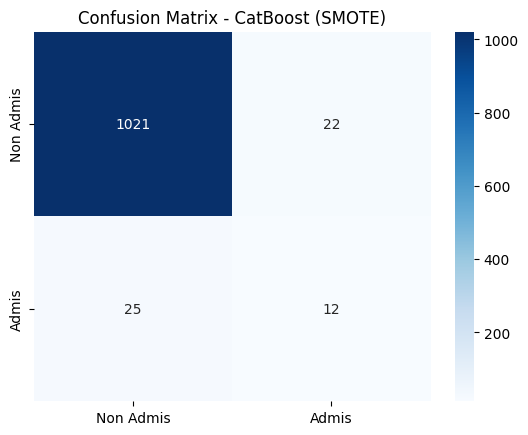


🌟 Modèle: Random Forest avec SMOTE
              precision    recall  f1-score   support

   Non Admis       0.97      0.99      0.98      1043
       Admis       0.62      0.27      0.38        37

    accuracy                           0.97      1080
   macro avg       0.80      0.63      0.68      1080
weighted avg       0.96      0.97      0.96      1080



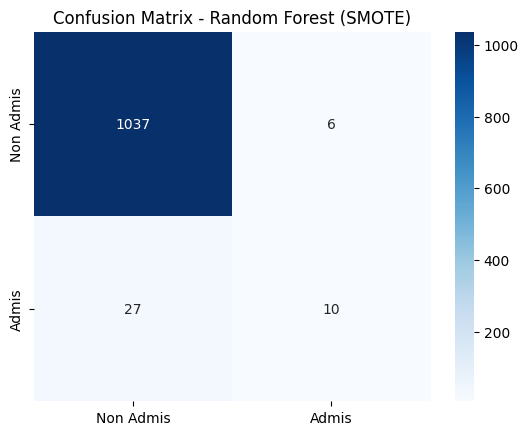


🌟 Modèle: SVM Coût avec SMOTE
              precision    recall  f1-score   support

   Non Admis       0.99      0.69      0.81      1043
       Admis       0.08      0.70      0.14        37

    accuracy                           0.69      1080
   macro avg       0.53      0.70      0.48      1080
weighted avg       0.95      0.69      0.79      1080



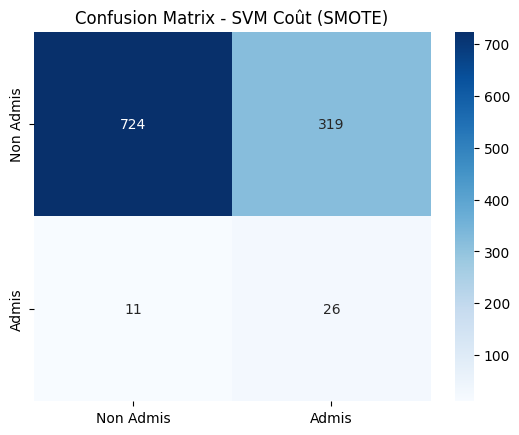


🌟 Modèle: Isolation Forest avec SMOTE
              precision    recall  f1-score   support

   Non Admis       0.96      0.96      0.96      1043
       Admis       0.00      0.00      0.00        37

    accuracy                           0.92      1080
   macro avg       0.48      0.48      0.48      1080
weighted avg       0.93      0.92      0.93      1080



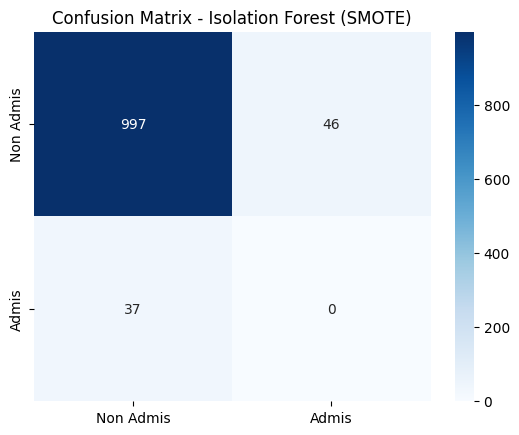


🌟 Modèle: MLP avec SMOTE
              precision    recall  f1-score   support

   Non Admis       0.97      0.92      0.94      1043
       Admis       0.11      0.27      0.15        37

    accuracy                           0.90      1080
   macro avg       0.54      0.59      0.55      1080
weighted avg       0.94      0.90      0.92      1080



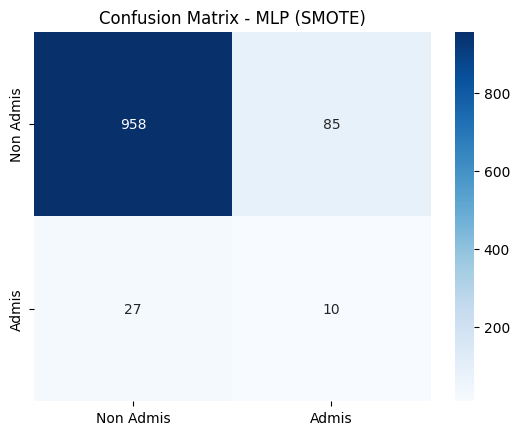


🔄 Rééchantillonnage : ADASYN
Distribution :
Admission
0    3129
1    1575
Name: count, dtype: int64

🌟 Modèle: XGBoost avec ADASYN
              precision    recall  f1-score   support

   Non Admis       0.98      1.00      0.99      1043
       Admis       0.69      0.30      0.42        37

    accuracy                           0.97      1080
   macro avg       0.83      0.65      0.70      1080
weighted avg       0.97      0.97      0.97      1080



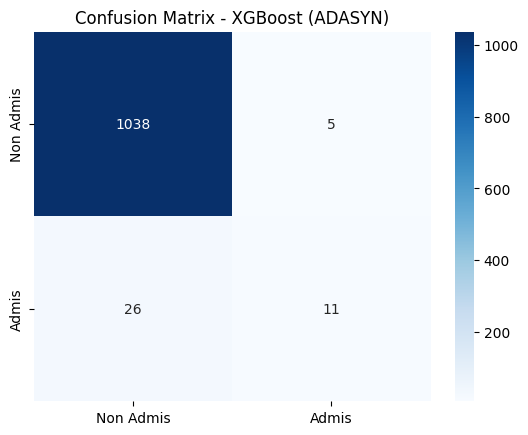


🌟 Modèle: LightGBM avec ADASYN
[LightGBM] [Info] Number of positive: 1575, number of negative: 3129
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000856 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1422
[LightGBM] [Info] Number of data points in the train set: 4704, number of used features: 22
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
              precision    recall  f1-score   support

   Non Admis       0.98      0.97      0.97      1043
       Admis       0.32      0.41      0.36        37

    accuracy                           0.95      1080
   macro avg       0.65      0.69      0.67      1080
weighted avg       0.96      0.95      0.95      1080



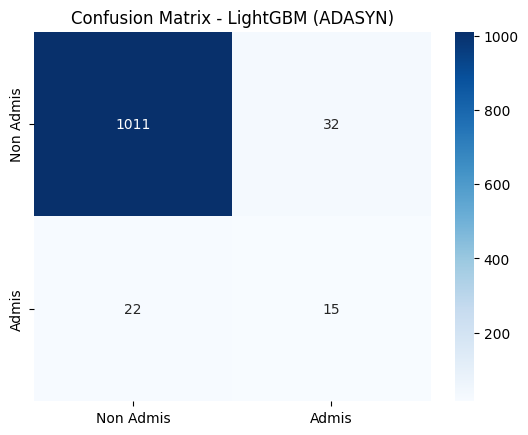


🌟 Modèle: CatBoost avec ADASYN
              precision    recall  f1-score   support

   Non Admis       0.98      0.97      0.98      1043
       Admis       0.34      0.41      0.37        37

    accuracy                           0.95      1080
   macro avg       0.66      0.69      0.67      1080
weighted avg       0.96      0.95      0.95      1080



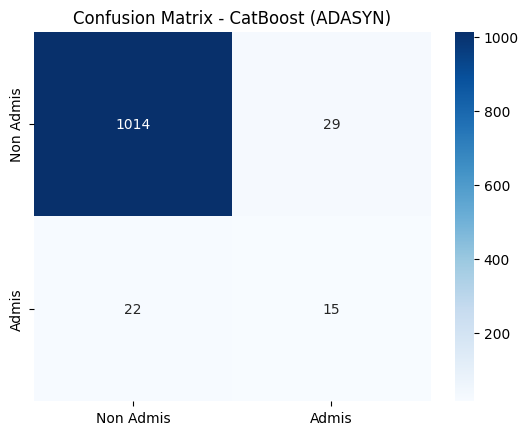


🌟 Modèle: Random Forest avec ADASYN
              precision    recall  f1-score   support

   Non Admis       0.98      0.99      0.98      1043
       Admis       0.61      0.30      0.40        37

    accuracy                           0.97      1080
   macro avg       0.79      0.65      0.69      1080
weighted avg       0.96      0.97      0.96      1080



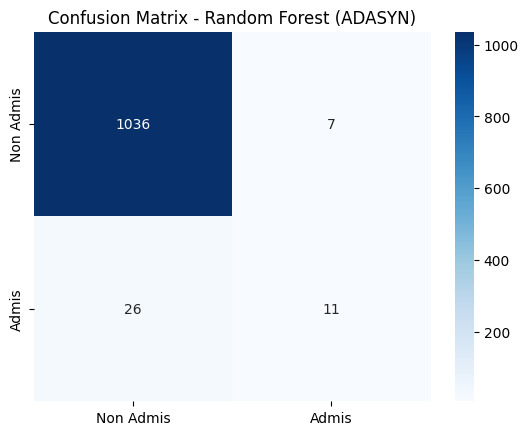


🌟 Modèle: SVM Coût avec ADASYN
              precision    recall  f1-score   support

   Non Admis       0.97      0.92      0.94      1043
       Admis       0.09      0.24      0.13        37

    accuracy                           0.89      1080
   macro avg       0.53      0.58      0.54      1080
weighted avg       0.94      0.89      0.92      1080



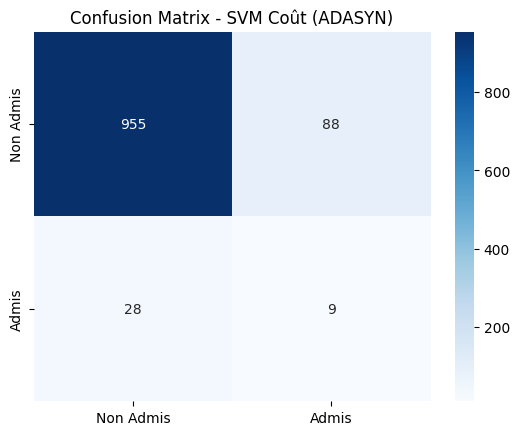


🌟 Modèle: Isolation Forest avec ADASYN
              precision    recall  f1-score   support

   Non Admis       0.96      0.96      0.96      1043
       Admis       0.00      0.00      0.00        37

    accuracy                           0.93      1080
   macro avg       0.48      0.48      0.48      1080
weighted avg       0.93      0.93      0.93      1080



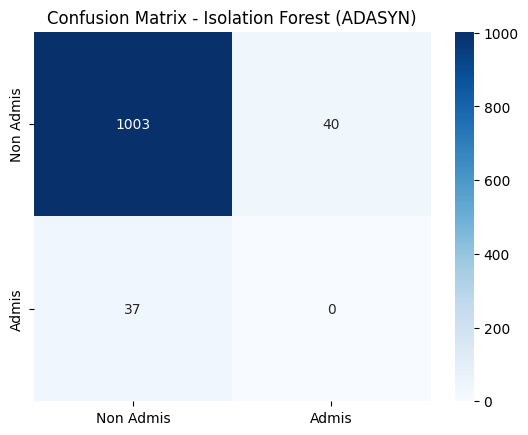


🌟 Modèle: MLP avec ADASYN
              precision    recall  f1-score   support

   Non Admis       0.97      0.91      0.94      1043
       Admis       0.09      0.27      0.14        37

    accuracy                           0.88      1080
   macro avg       0.53      0.59      0.54      1080
weighted avg       0.94      0.88      0.91      1080



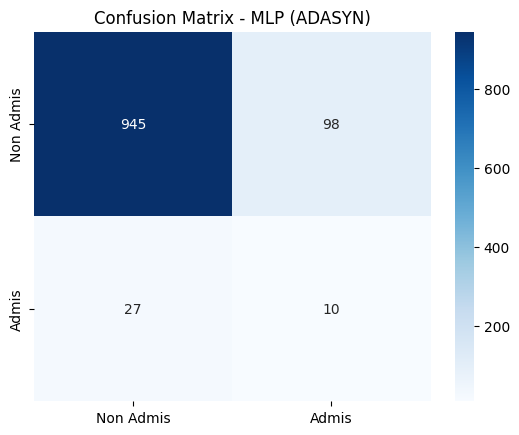


🔄 Rééchantillonnage : SMOTE-Tomek
Distribution :
Admission
0    3127
1    3127
Name: count, dtype: int64

🌟 Modèle: XGBoost avec SMOTE-Tomek
              precision    recall  f1-score   support

   Non Admis       0.97      1.00      0.98      1043
       Admis       0.64      0.24      0.35        37

    accuracy                           0.97      1080
   macro avg       0.81      0.62      0.67      1080
weighted avg       0.96      0.97      0.96      1080



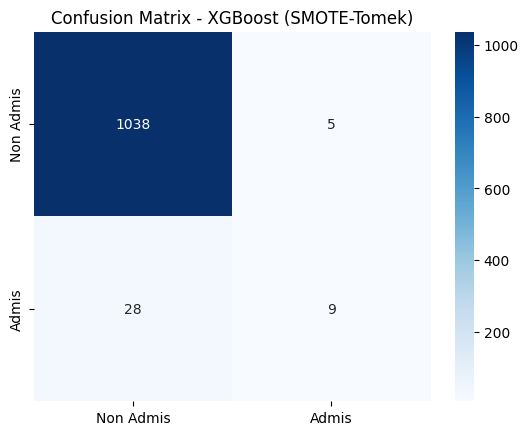


🌟 Modèle: LightGBM avec SMOTE-Tomek
[LightGBM] [Info] Number of positive: 3127, number of negative: 3127
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002092 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1422
[LightGBM] [Info] Number of data points in the train set: 6254, number of used features: 22
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
              precision    recall  f1-score   support

   Non Admis       0.98      0.97      0.97      1043
       Admis       0.31      0.41      0.35        37

    accuracy                           0.95      1080
   macro avg       0.65      0.69      0.66      1080
weighted avg       0.96      0.95      0.95      1080



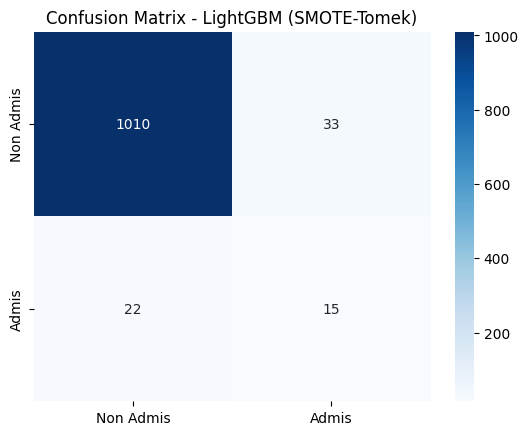


🌟 Modèle: CatBoost avec SMOTE-Tomek
              precision    recall  f1-score   support

   Non Admis       0.98      0.96      0.97      1043
       Admis       0.27      0.41      0.32        37

    accuracy                           0.94      1080
   macro avg       0.62      0.68      0.65      1080
weighted avg       0.95      0.94      0.95      1080



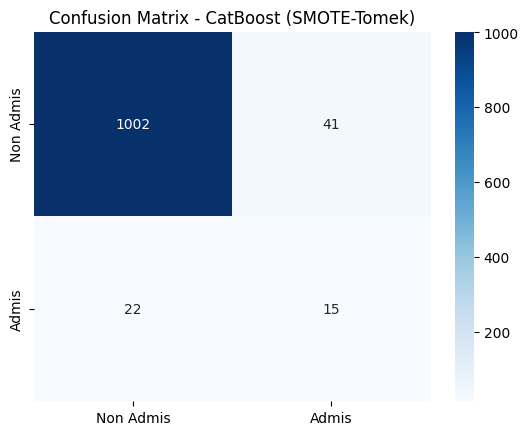


🌟 Modèle: Random Forest avec SMOTE-Tomek
              precision    recall  f1-score   support

   Non Admis       0.97      0.99      0.98      1043
       Admis       0.59      0.27      0.37        37

    accuracy                           0.97      1080
   macro avg       0.78      0.63      0.68      1080
weighted avg       0.96      0.97      0.96      1080



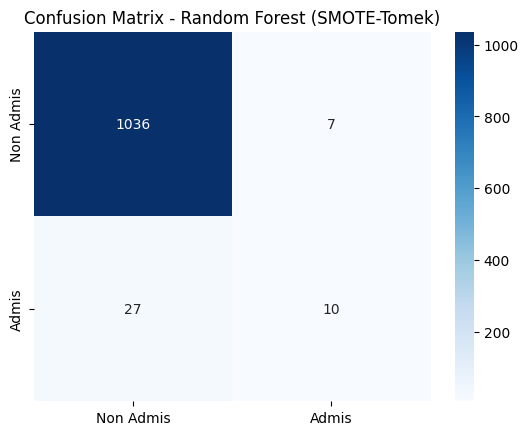


🌟 Modèle: SVM Coût avec SMOTE-Tomek
              precision    recall  f1-score   support

   Non Admis       0.97      0.93      0.95      1043
       Admis       0.10      0.22      0.14        37

    accuracy                           0.91      1080
   macro avg       0.54      0.57      0.54      1080
weighted avg       0.94      0.91      0.92      1080



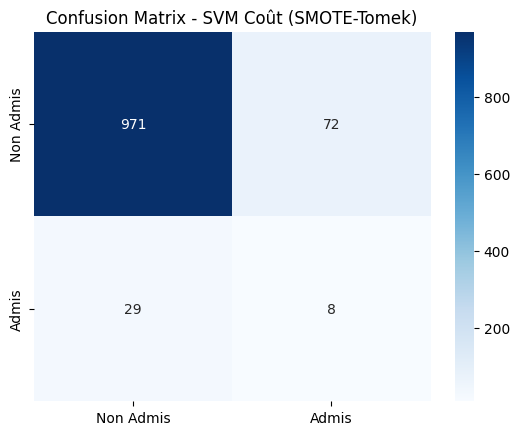


🌟 Modèle: Isolation Forest avec SMOTE-Tomek
              precision    recall  f1-score   support

   Non Admis       0.96      0.96      0.96      1043
       Admis       0.00      0.00      0.00        37

    accuracy                           0.93      1080
   macro avg       0.48      0.48      0.48      1080
weighted avg       0.93      0.93      0.93      1080



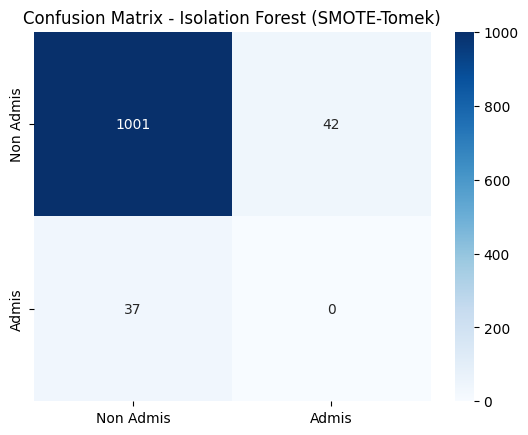


🌟 Modèle: MLP avec SMOTE-Tomek
              precision    recall  f1-score   support

   Non Admis       0.97      0.91      0.94      1043
       Admis       0.10      0.30      0.15        37

    accuracy                           0.88      1080
   macro avg       0.54      0.60      0.54      1080
weighted avg       0.94      0.88      0.91      1080



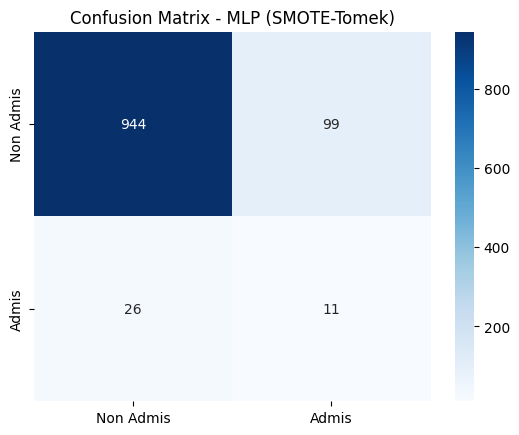


🎯 Résumé Comparatif (Validation Set) :


,Méthode,Modèle,F1-Admis,Best Threshold,Matrice de Confusion
7,ADASYN,XGBoost,0.415094,9.720219e-01,"[[1038, 5], [26, 11]]"
10,ADASYN,Random Forest,0.400000,6.700000e-01,"[[1036, 7], [26, 11]]"
3,SMOTE,Random Forest,0.377358,7.600000e-01,"[[1037, 6], [27, 10]]"
17,SMOTE-Tomek,Random Forest,0.370370,7.600000e-01,"[[1036, 7], [27, 10]]"
9,ADASYN,CatBoost,0.370370,6.352552e-01,"[[1014, 29], [22, 15]]"
8,ADASYN,LightGBM,0.357143,6.345453e-01,"[[1011, 32], [22, 15]]"
14,SMOTE-Tomek,XGBoost,0.352941,9.809288e-01,"[[1038, 5], [28, 9]]"
15,SMOTE-Tomek,LightGBM,0.352941,6.266571e-01,"[[1010, 33], [22, 15]]"
0,SMOTE,XGBoost,0.346154,9.830063e-01,"[[1037, 6], [28, 9]]"
2,SMOTE,CatBoost,0.338028,7.221713e-01,"[[1021, 22], [25, 12]]"


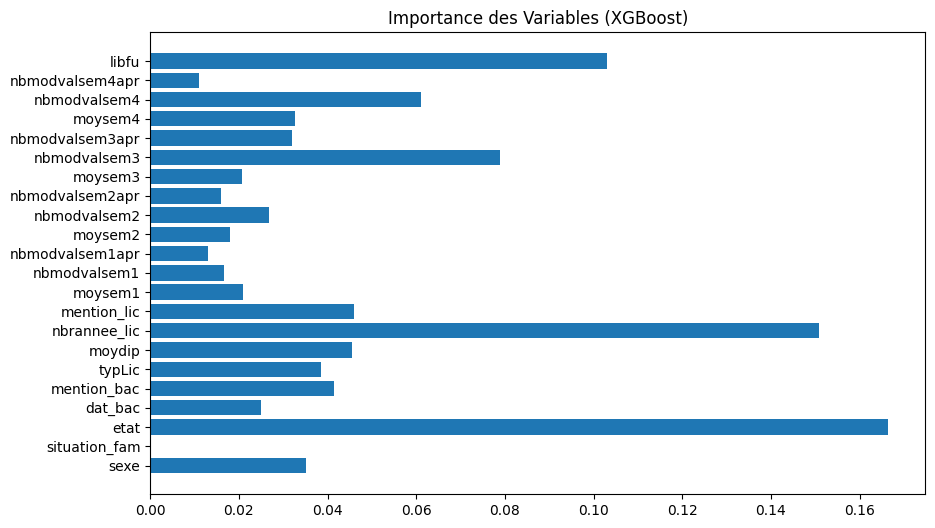

In [ ]:
# 🔁 3. Rééchantillonnage sur le train uniquement
samplers = {
    "SMOTE": SMOTE(random_state=42),
    "ADASYN": ADASYN(random_state=42, sampling_strategy=0.5),
    "SMOTE-Tomek": SMOTETomek(random_state=42)
}

# 📚 4. Modèles à tester
models = {
    "XGBoost": XGBClassifier(scale_pos_weight=5, eval_metric='aucpr', random_state=42),
    "LightGBM": LGBMClassifier(class_weight='balanced', random_state=42),
    "CatBoost": CatBoostClassifier(auto_class_weights='Balanced', silent=True, random_state=42),
    "Random Forest": RandomForestClassifier(class_weight='balanced', random_state=42),
    "SVM Coût": SVC(class_weight={0:1, 1:10}, kernel='rbf', probability=True, random_state=42),
    "Isolation Forest": IsolationForest(contamination=0.03, random_state=42),
    "MLP": MLPClassifier(hidden_layer_sizes=(50, 25), early_stopping=True, random_state=42)
}

# 📊 5. Entraînement et Évaluation sur Validation
results = []

for sampler_name, sampler in samplers.items():
    print(f"\n🔄 Rééchantillonnage : {sampler_name}")
    X_res, y_res = sampler.fit_resample(X_train, y_train)
    print(f"Distribution :\n{pd.Series(y_res).value_counts()}")

    for model_name, model in models.items():
        print(f"\n🌟 Modèle: {model_name} avec {sampler_name}")

        if model_name == "Isolation Forest":
            model.fit(X_res)
            y_pred = (model.predict(X_val) == -1).astype(int)
            y_true = y_val
        else:
            model.fit(X_res, y_res)
            y_true = y_val
            if hasattr(model, "predict_proba"):
                y_proba = model.predict_proba(X_val)[:, 1]
                precision, recall, thresholds = precision_recall_curve(y_val, y_proba)
                f1_scores = 2 * (precision * recall) / (precision + recall + 1e-6)
                best_threshold = thresholds[np.argmax(f1_scores)]
                y_pred = (y_proba >= best_threshold).astype(int)
            else:
                y_pred = model.predict(X_val)
                best_threshold = None

        report = classification_report(y_true, y_pred, target_names=["Non Admis", "Admis"])
        print(report)

        cm = confusion_matrix(y_true, y_pred)
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                    xticklabels=["Non Admis", "Admis"],
                    yticklabels=["Non Admis", "Admis"])
        plt.title(f"Confusion Matrix - {model_name} ({sampler_name})")
        plt.show()

        results.append({
            "Méthode": sampler_name,
            "Modèle": model_name,
            "F1-Admis": f1_score(y_true, y_pred, pos_label=1),
            "Best Threshold": best_threshold,
            "Matrice de Confusion": cm
        })

# 📋 6. Résumé des résultats
results_df = pd.DataFrame(results)
print("\n🎯 Résumé Comparatif (Validation Set) :")
display(results_df.sort_values(by="F1-Admis", ascending=False))

# 🔍 7. Importance des variables (optionnel)
xgb = XGBClassifier(scale_pos_weight=5, eval_metric='aucpr')
xgb.fit(X_res, y_res)
plt.figure(figsize=(10, 6))
plt.barh(X.columns, xgb.feature_importances_)
plt.title("Importance des Variables (XGBoost)")
plt.show()

In [ ]:
# 🔁 Rééchantillonnage uniquement pour les couples nécessaires
X_adasyn, y_adasyn = ADASYN(random_state=42).fit_resample(X_train, y_train)
X_smote, y_smote = SMOTE(random_state=42).fit_resample(X_train, y_train)

# 🎯 Grilles d'hyperparamètres
param_grids = {
    "XGBoost": {
        'n_estimators': [100, 200],
        'max_depth': [3, 6, 10],
        'learning_rate': [0.1, 0.3],
        'subsample': [0.8, 1],
        'colsample_bytree': [0.8, 1]
    },
    "RandomForest": {
        'n_estimators': [100, 200],
        'max_depth': [5, 10, 15],
        'min_samples_split': [2, 5]
    }
}

# 📊 Résultats
results_optim = []

# 1️⃣ ADASYN + XGBoost
print("\n🔍 GridSearchCV : ADASYN + XGBoost")
xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
grid_xgb = GridSearchCV(xgb, param_grids["XGBoost"], scoring='f1', cv=3, n_jobs=-1, verbose=1)
grid_xgb.fit(X_adasyn, y_adasyn)
y_pred = grid_xgb.best_estimator_.predict(X_val)
results_optim.append({
    "Méthode": "ADASYN",
    "Modèle": "XGBoost",
    "F1-Admis": f1_score(y_val, y_pred, pos_label=1),
    "Recall-Admis": recall_score(y_val, y_pred, pos_label=1),
    "Best Params": grid_xgb.best_params_
})

# 2️⃣ ADASYN + RandomForest
print("\n🔍 GridSearchCV : ADASYN + RandomForest")
rf_adasyn = RandomForestClassifier(class_weight='balanced', random_state=42)
grid_rf_adasyn = GridSearchCV(rf_adasyn, param_grids["RandomForest"], scoring='f1', cv=3, n_jobs=-1, verbose=1)
grid_rf_adasyn.fit(X_adasyn, y_adasyn)
y_pred = grid_rf_adasyn.best_estimator_.predict(X_val)
results_optim.append({
    "Méthode": "ADASYN",
    "Modèle": "RandomForest",
    "F1-Admis": f1_score(y_val, y_pred, pos_label=1),
    "Recall-Admis": recall_score(y_val, y_pred, pos_label=1),
    "Best Params": grid_rf_adasyn.best_params_
})

# 3️⃣ SMOTE + RandomForest
print("\n🔍 GridSearchCV : SMOTE + RandomForest")
rf_smote = RandomForestClassifier(class_weight='balanced', random_state=42)
grid_rf_smote = GridSearchCV(rf_smote, param_grids["RandomForest"], scoring='f1', cv=3, n_jobs=-1, verbose=1)
grid_rf_smote.fit(X_smote, y_smote)
y_pred = grid_rf_smote.best_estimator_.predict(X_val)
results_optim.append({
    "Méthode": "SMOTE",
    "Modèle": "RandomForest",
    "F1-Admis": f1_score(y_val, y_pred, pos_label=1),
    "Recall-Admis": recall_score(y_val, y_pred, pos_label=1),
    "Best Params": grid_rf_smote.best_params_
})

# 📋 Résultats finaux
df_optim = pd.DataFrame(results_optim).sort_values(by="F1-Admis", ascending=False).reset_index(drop=True)
print("\n✅ Résumé des modèles optimisés (validation) :")
display(df_optim)



🔍 GridSearchCV : ADASYN + XGBoost
Fitting 3 folds for each of 48 candidates, totalling 144 fits


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [11:37:59] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)



🔍 GridSearchCV : ADASYN + RandomForest
Fitting 3 folds for each of 12 candidates, totalling 36 fits

🔍 GridSearchCV : SMOTE + RandomForest
Fitting 3 folds for each of 12 candidates, totalling 36 fits

✅ Résumé des modèles optimisés (validation) :


,Méthode,Modèle,F1-Admis,Recall-Admis,Best Params
0,ADASYN,XGBoost,0.317073,0.351351,"{'colsample_bytree': 0.8, 'learning_rate': 0.3..."
1,ADASYN,RandomForest,0.273684,0.351351,"{'max_depth': 15, 'min_samples_split': 2, 'n_e..."
2,SMOTE,RandomForest,0.233010,0.324324,"{'max_depth': 15, 'min_samples_split': 5, 'n_e..."


In [ ]:
# 🎯 Réduction ciblée du déséquilibre : garder tous les admis et 2x ou 3x plus de non admis

# 1. Séparer les deux classes
df_admis = df[df['Admission'] == 1]
df_non_admis = df[df['Admission'] == 0]

# 2. Réduire les non admis (ici ×2, tu peux mettre ×3 si tu veux)
non_admis_sample = df_non_admis.sample(n=len(df_admis)*2, random_state=42)

# 3. Combiner admis + non admis réduits
df_reduit = pd.concat([df_admis, non_admis_sample], axis=0)

# 4. Mélanger l’ensemble
df_reduit = df_reduit.sample(frac=1, random_state=42).reset_index(drop=True)

# 5. Mise à jour des features (X) et target (y)
X = df_reduit.drop(columns=['Admission'])
y = df_reduit['Admission']

# 🔎 Vérification
print(f"✅ Nouvelle forme du dataset réduit : {df_reduit.shape}")
print(df_reduit['Admission'].value_counts())


✅ Nouvelle forme du dataset réduit : (555, 23)
Admission
0    370
1    185
Name: count, dtype: int64


In [ ]:
# Séparation en train/test d’abord (20% test), puis train/val (25% de train)
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42)

print(f"✅ Train : {X_train.shape}, Val : {X_val.shape}, Test : {X_test.shape}")


✅ Train : (333, 22), Val : (111, 22), Test : (111, 22)


In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)


In [ ]:
# Rééchantillonnage sur les données d'entraînement uniquement
X_adasyn, y_adasyn = ADASYN(random_state=42).fit_resample(X_train_scaled, y_train)
X_smote, y_smote = SMOTE(random_state=42).fit_resample(X_train_scaled, y_train)

# Vérification des tailles
print("📊 Après ADASYN :", pd.Series(y_adasyn).value_counts().to_dict())
print("📊 Après SMOTE :", pd.Series(y_smote).value_counts().to_dict())


📊 Après ADASYN : {0: 222, 1: 208}
📊 Après SMOTE : {0: 222, 1: 222}


🏆 Meilleur modèle sélectionné : XGBoost (ADASYN)
Hyperparamètres optimaux : {'colsample_bytree': 0.8, 'learning_rate': 0.3, 'max_depth': 10, 'n_estimators': 200, 'subsample': 0.8}

🏋️ Entraînement du modèle final (XGBoost avec ADASYN) sur Train+Validation...
✅ Entraînement terminé.

🚀 Évaluation finale sur le jeu de test...

📊 Classification Report (Test Set) :


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [11:39:21] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


              precision    recall  f1-score   support

   Non Admis       0.86      0.82      0.84        74
       Admis       0.68      0.73      0.70        37

    accuracy                           0.79       111
   macro avg       0.77      0.78      0.77       111
weighted avg       0.80      0.79      0.79       111



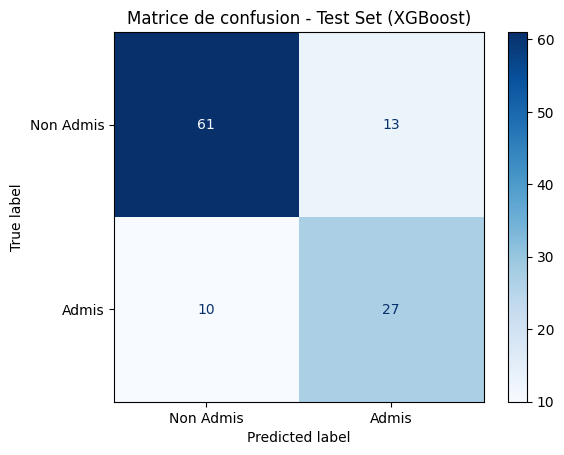


🎯 F1-score final sur le test set : 0.701


In [ ]:

# 🏆 Sélection du meilleur modèle basé sur le F1-score sur validation
best_model_info = df_optim.iloc[0]
best_method = best_model_info['Méthode']
best_model_name = best_model_info['Modèle']
best_params = best_model_info['Best Params']

print(f"🏆 Meilleur modèle sélectionné : {best_model_name} ({best_method})")
print(f"Hyperparamètres optimaux : {best_params}")

# 🛠️ Entraîner le modèle final sur le jeu combiné Train + Validation, en utilisant la meilleure méthode de rééchantillonnage et les meilleurs hyperparamètres
if best_method == "ADASYN":
    sampler_final = ADASYN(random_state=42)
    X_train_val_res, y_train_val_res = sampler_final.fit_resample(np.vstack((X_train_scaled, X_val_scaled)), np.concatenate((y_train, y_val)))
elif best_method == "SMOTE":
    sampler_final = SMOTE(random_state=42)
    X_train_val_res, y_train_val_res = sampler_final.fit_resample(np.vstack((X_train_scaled, X_val_scaled)), np.concatenate((y_train, y_val)))
else:
    # Si c'est class_weight, pas de rééchantillonnage
    X_train_val_res = np.vstack((X_train_scaled, X_val_scaled))
    y_train_val_res = np.concatenate((y_train, y_val))


if best_model_name == "XGBoost":
    final_model = XGBClassifier(**best_params, use_label_encoder=False, eval_metric='logloss', random_state=42)
elif best_model_name == "RandomForest":
    final_model = RandomForestClassifier(**best_params, class_weight='balanced', random_state=42)
# Ajoute ici les autres modèles si nécessaire (SVM, etc.)

print(f"\n🏋️ Entraînement du modèle final ({best_model_name} avec {best_method}) sur Train+Validation...")
final_model.fit(X_train_val_res, y_train_val_res)
print("✅ Entraînement terminé.")


# 🏅 Évaluation finale sur le jeu de test
print("\n🚀 Évaluation finale sur le jeu de test...")
y_test_pred = final_model.predict(X_test_scaled)

print("\n📊 Classification Report (Test Set) :")
print(classification_report(y_test, y_test_pred, target_names=["Non Admis", "Admis"]))

# Matrice de confusion sur le test set
cm_test = confusion_matrix(y_test, y_test_pred)
disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=["Non Admis", "Admis"])
disp_test.plot(cmap='Blues')
plt.title(f"Matrice de confusion - Test Set ({best_model_name})")
plt.show()

# Calcul du F1-score sur le test set
f1_final = f1_score(y_test, y_test_pred, pos_label=1)
print(f"\n🎯 F1-score final sur le test set : {f1_final:.3f}")




In [ ]:
#1 Sauvegarde du modèle entraîné
import joblib # Import the joblib library
joblib.dump(final_model, "meilleur_modele_admission.pkl")

joblib.dump(label_encoders, 'label_encoders.pkl')

joblib.dump(scaler, 'scaler.pkl')

# Sauvegarder la liste exacte des colonnes utilisées pour l'entraînement
joblib.dump(X.columns.tolist(), 'X_columns.pkl')

print("✅ Tous les objets ont été sauvegardés avec succès.")

✅ Tous les objets ont été sauvegardés avec succès.
